# Risk-Neutral Density Extraction — AAPL Options

**Research question:** What does the options market imply about the 30-day return distribution of AAPL?

**Methods:**
- **Breeden-Litzenberger (1978):** $f^Q(K) = e^{r\tau} \partial^2C/\partial K^2$ — model-free
- **SVI:** parametric 5-parameter smile fit (Gatheral 2004)
- **SSVI:** arbitrage-free surface extension (Gatheral & Jacquier 2013)

**Key result:** The implied RND is left-skewed and fat-tailed vs. normal — quantifying the crash risk premium embedded in option prices. The VRP (implied − realised vol) is directly visible from the RND's standard deviation.

## 1. Imports

In [8]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import logging
from datetime import datetime, timedelta
from scipy.stats import norm, gaussian_kde
import yfinance as yf

from options_analytics import (
    select_expiry, compute_tau, preprocess_options,
    compute_option_ivs, trapezoidal, extract_rnd_bl,
    svi_total_var, calibrate_svi, rnd_from_svi,
    ssvi_total_var, calibrate_ssvi, rnd_from_ssvi,
    compute_tail_metrics, clip_normalise,
)

logging.getLogger("yfinance").setLevel(logging.ERROR)
logging.getLogger("peewee").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="scipy")

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.titlesize": 12})

## 2. Data Loading

In [9]:
TICKER     = "AAPL"
TARGET_DTE = 30
MIN_OI     = 100
MAX_SPREAD = 0.25   # bid-ask / mid

stock = yf.Ticker(TICKER)

# Current price
try:
    S0 = float(stock.fast_info["last_price"])
except Exception:
    S0 = float(stock.history(period="1d")["Close"].iloc[-1])

# Nearest expiry to TARGET_DTE
expiration = select_expiry(stock, TARGET_DTE)
tau        = compute_tau(expiration)

# Risk-free rate (3m T-bill)
try:
    r = float(yf.Ticker("^IRX").history(period="5d")["Close"].dropna().iloc[-1]) / 100
except Exception:
    r = 0.04

# Dividend yield — guard against yfinance unit error (returns 42 instead of 0.0042)
try:
    q = yf.Ticker(TICKER).info.get("dividendYield", 0.0) or 0.0
    if q > 0.20: q /= 100   # Fix F1: yfinance sometimes returns percentage, not decimal
except Exception:
    q = 0.0

F = S0 * np.exp((r - q) * tau)   # forward price

print(f"{TICKER}  |  S₀={S0:.2f}  F={F:.2f}  r={r:.3%}  q={q:.3%}")
print(f"Expiry: {expiration}  ({tau*365.25:.1f} calendar days)")

# Download option chain with liquidity filters
def load_chain(stock, expiration, min_oi, max_spread):
    chain = stock.option_chain(expiration)
    out = {}
    for side, df in [("call", chain.calls), ("put", chain.puts)]:
        df = df.copy()
        df["midPrice"]  = (df["bid"] + df["ask"]) / 2
        df["relSpread"] = (df["ask"] - df["bid"]) / df["midPrice"].replace(0, np.nan)
        out[side] = df[(df["openInterest"] >= min_oi) &
                       (df["relSpread"] < max_spread) &
                       (df["midPrice"] > 0)].copy()
    return out["call"], out["put"]

calls_raw, puts_raw = load_chain(stock, expiration, MIN_OI, MAX_SPREAD)
print(f"Liquid calls: {len(calls_raw)}  |  Liquid puts: {len(puts_raw)}")

AAPL  |  S₀=253.79  F=254.45  r=3.600%  q=0.420%
Expiry: 2026-05-01  (30.0 calendar days)
Liquid calls: 15  |  Liquid puts: 15


## 3. Preprocessing — Put-Call Stitching & Implied Vols

OTM puts below ATM, OTM calls above ATM — maximises liquidity across the smile.

Options after stitching: 21  |  Valid IVs: 21
Call monotonicity violations: 0  (0 = arb-free)


/var/folders/3m/lvmf3szd2mb891zfkzyg9mmw0000gn/T/ipykernel_36539/4145463573.py:29: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


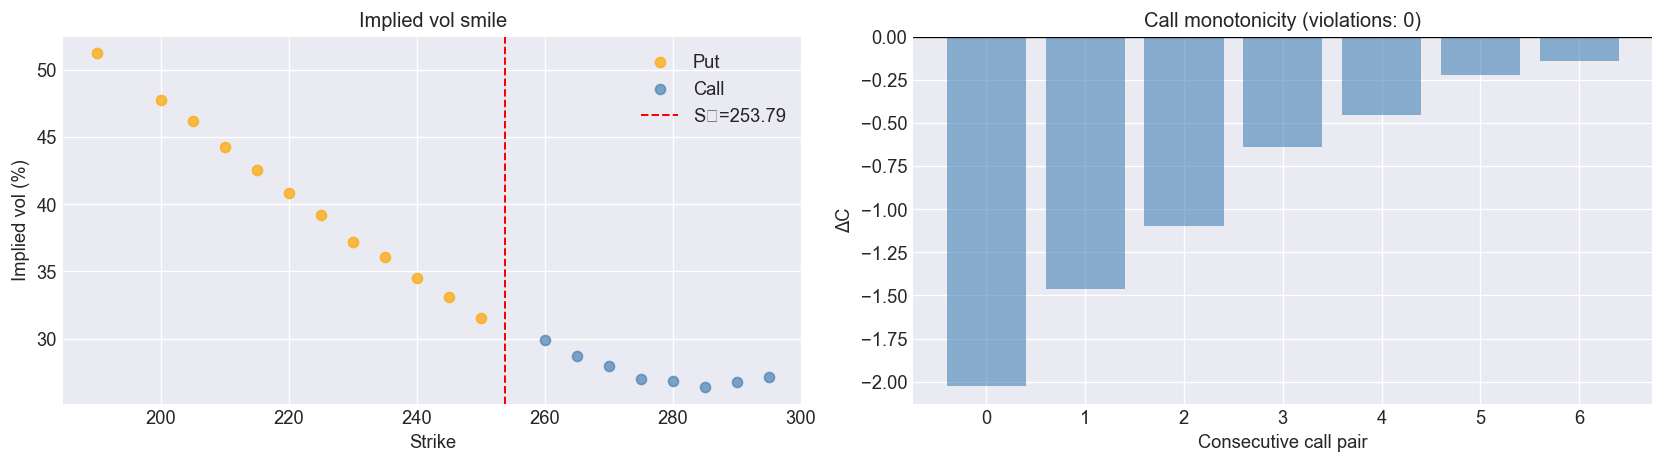

In [10]:
# Stitch OTM chain and compute implied vols
options_df = preprocess_options(calls_raw, puts_raw, S0, F, tau)
options_df = compute_option_ivs(options_df, S0, tau, r, q)
valid = options_df.dropna(subset=["iv"]).copy()

print(f"Options after stitching: {len(options_df)}  |  Valid IVs: {len(valid)}")

# No-arbitrage check: OTM call prices should be monotone decreasing in K
calls_sorted = valid[valid["optionType"]=="call"].sort_values("strike")
n_viol = (np.diff(calls_sorted["midPrice"].values) > 0).sum()
print(f"Call monotonicity violations: {n_viol}  (0 = arb-free)")

# Smile overview
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for otype, color in [("put", "orange"), ("call", "steelblue")]:
    sub = valid[valid["optionType"]==otype]
    axes[0].scatter(sub["strike"], sub["iv"]*100, color=color, alpha=0.7, label=otype.capitalize())
axes[0].axvline(S0, color="red", ls="--", lw=1.2, label=f"S₀={S0:.2f}")
axes[0].set(xlabel="Strike", ylabel="Implied vol (%)", title="Implied vol smile")
axes[0].legend()

axes[1].bar(range(len(np.diff(calls_sorted["midPrice"].values))),
            np.diff(calls_sorted["midPrice"].values),
            color=np.where(np.diff(calls_sorted["midPrice"].values) > 0, "red", "steelblue"), alpha=0.6)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="Consecutive call pair", ylabel="ΔC",
            title=f"Call monotonicity (violations: {n_viol})")
plt.tight_layout(); plt.show()

## 4. Breeden-Litzenberger RND (Model-Free)

$f^Q(K) = e^{r\tau} \frac{\partial^2 C}{\partial K^2}$

**Key fix (R1):** Puts converted to call-equivalent via put-call parity before interpolation. The mixed put/call stitched chain peaks at ATM, so $\partial C/\partial K > 0$ on the put side — a no-arb violation. Converting to calls gives a monotone decreasing price curve, which Pchip interpolates cleanly.

B-L RND  |  E^Q[S_T]=254.31  std=19.59  F=254.45  |  discrepancy=0.15


/var/folders/3m/lvmf3szd2mb891zfkzyg9mmw0000gn/T/ipykernel_36539/3745779458.py:28: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()


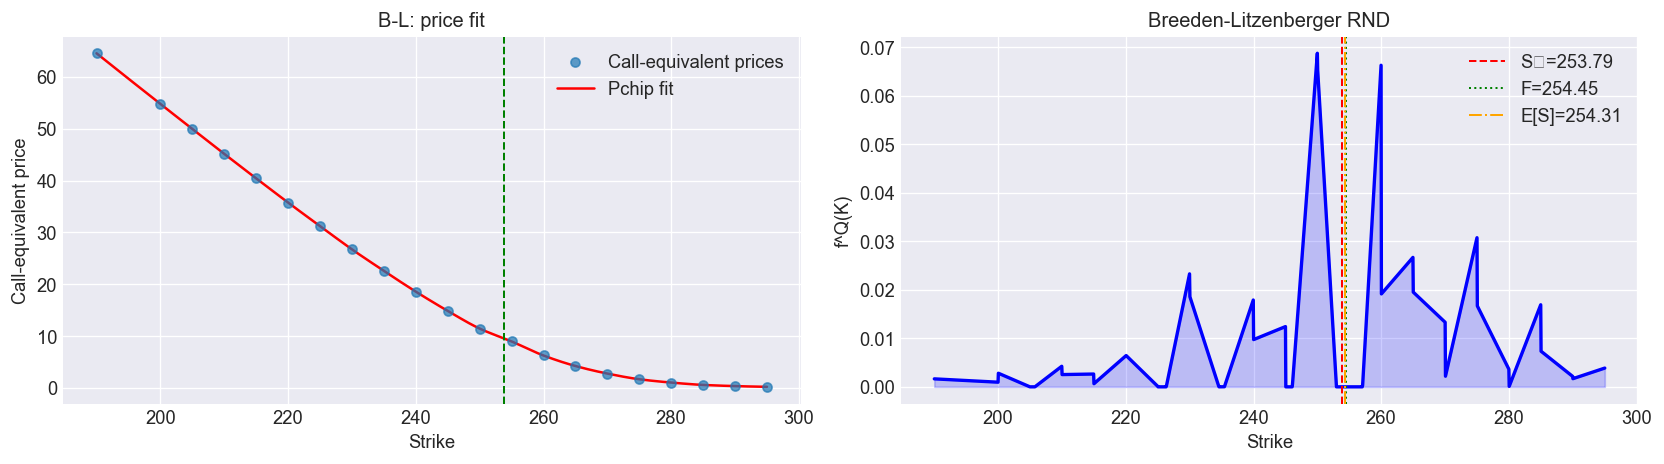

In [11]:
# Convert puts to call-equivalent so price curve is monotone decreasing (Fix R1)
disc = np.exp(-r * tau)
C_equiv = np.where(
    valid["optionType"].values == "put",
    valid["midPrice"].values + F * disc - valid["strike"].values * disc,
    valid["midPrice"].values
)
K_bl = valid["strike"].values

K_fine, rnd_bl, dC_dK, d2C_dK2, spl_bl = extract_rnd_bl(K_bl, C_equiv, S0=S0, r=r, q=q, tau=tau)

mean_bl = trapezoidal(K_fine * rnd_bl, K_fine)
std_bl  = np.sqrt(trapezoidal((K_fine - mean_bl)**2 * rnd_bl, K_fine))
print(f"B-L RND  |  E^Q[S_T]={mean_bl:.2f}  std={std_bl:.2f}  F={F:.2f}  |  discrepancy={abs(mean_bl-F):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(K_bl, C_equiv, s=30, alpha=0.7, zorder=3, label="Call-equivalent prices")
axes[0].plot(K_fine, spl_bl(K_fine), "r-", lw=1.5, label="Pchip fit")
axes[0].axvline(S0, color="green", ls="--", lw=1.2)
axes[0].set(xlabel="Strike", ylabel="Call-equivalent price", title="B-L: price fit"); axes[0].legend()

axes[1].plot(K_fine, rnd_bl, "b-", lw=2)
axes[1].fill_between(K_fine, 0, rnd_bl, alpha=0.2, color="blue")
axes[1].axvline(S0,     color="red",    ls="--", lw=1.2, label=f"S₀={S0:.2f}")
axes[1].axvline(F,      color="green",  ls=":",  lw=1.2, label=f"F={F:.2f}")
axes[1].axvline(mean_bl, color="orange", ls="-.", lw=1.2, label=f"E[S]={mean_bl:.2f}")
axes[1].set(xlabel="Strike", ylabel="f^Q(K)", title="Breeden-Litzenberger RND"); axes[1].legend()
plt.tight_layout(); plt.show()

## 5. SVI Calibration

Parametric smile: $w(k) = a + b\left[\rho(k-m) + \sqrt{(k-m)^2 + \sigma^2}\right]$

Objective in **total-variance space** ($w = \sigma^2 T$), not raw IV — avoids heteroskedastic residuals. $\sigma$ lower-bounded at 0.05 to prevent degenerate V-shape density.

SVI  |  a=0.0000  b=0.0393  ρ=-0.5503  m=0.0324  σ=0.1777
     |  ATM IV=30.81%  SSE=6.56e-07


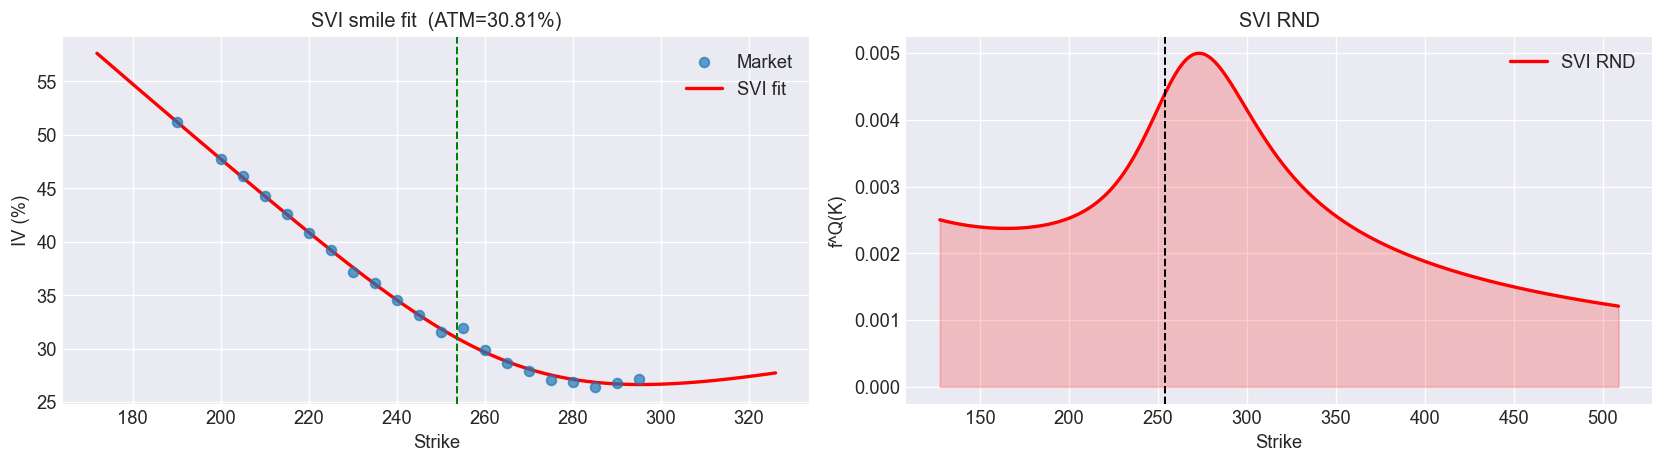

In [12]:
svi_res = calibrate_svi(valid["strike"].values, valid["iv"].values, F, tau)
a, b, rho_svi, m, sigma = svi_res["params"]

print(f"SVI  |  a={a:.4f}  b={b:.4f}  ρ={rho_svi:.4f}  m={m:.4f}  σ={sigma:.4f}")
print(f"     |  ATM IV={svi_res['atm_iv']:.2%}  SSE={svi_res['sse']:.2e}")

if sigma < 0.05:
    print(f"  [WARNING] σ={sigma:.4f} < 0.05 — smile nearly V-shaped, density may be degenerate")

# SVI RND
k_fine  = np.linspace(np.log(0.50), np.log(2.00), 3000)
rnd_svi_raw, K_svi, *_ = rnd_from_svi(k_fine, a, b, rho_svi, m, sigma, F)
rnd_svi = rnd_svi_raw / trapezoidal(rnd_svi_raw, K_svi)   # normalise

# Smile fit plot
k_mkt   = np.log(valid["strike"].values / F)
k_plot  = np.linspace(k_mkt.min() - 0.1, k_mkt.max() + 0.1, 500)
iv_fit  = np.sqrt(np.maximum(svi_total_var(k_plot, a, b, rho_svi, m, sigma) / tau, 0))
K_plot  = F * np.exp(k_plot)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(valid["strike"], valid["iv"]*100, s=35, alpha=0.7, zorder=3, label="Market")
axes[0].plot(K_plot, iv_fit*100, "r-", lw=2, label="SVI fit")
axes[0].axvline(S0, color="green", ls="--", lw=1.2)
axes[0].set(xlabel="Strike", ylabel="IV (%)", title=f"SVI smile fit  (ATM={svi_res['atm_iv']:.2%})"); axes[0].legend()

axes[1].plot(K_svi, rnd_svi, "r-", lw=2, label="SVI RND")
axes[1].fill_between(K_svi, 0, rnd_svi, alpha=0.2, color="red")
axes[1].axvline(S0, color="k", ls="--", lw=1.2)
axes[1].set(xlabel="Strike", ylabel="f^Q(K)", title="SVI RND"); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. SSVI Calibration (Arbitrage-Free)

$w(k;\theta,\phi,\rho) = \frac{\theta}{2}\left[1 + \rho\phi k + \sqrt{(\phi k+\rho)^2 + (1-\rho^2)}\right]$

No-butterfly constraint: $\phi\theta \leq 4$. Upper bound set dynamically to $\min(50,\,4/\theta)$.

SSVI |  θ=0.0077  φ=9.0063  ρ=-0.4787
     |  ATM IV=30.61%  SSE=1.43e-06  φ·θ=0.0693 ≤ 4 ✓


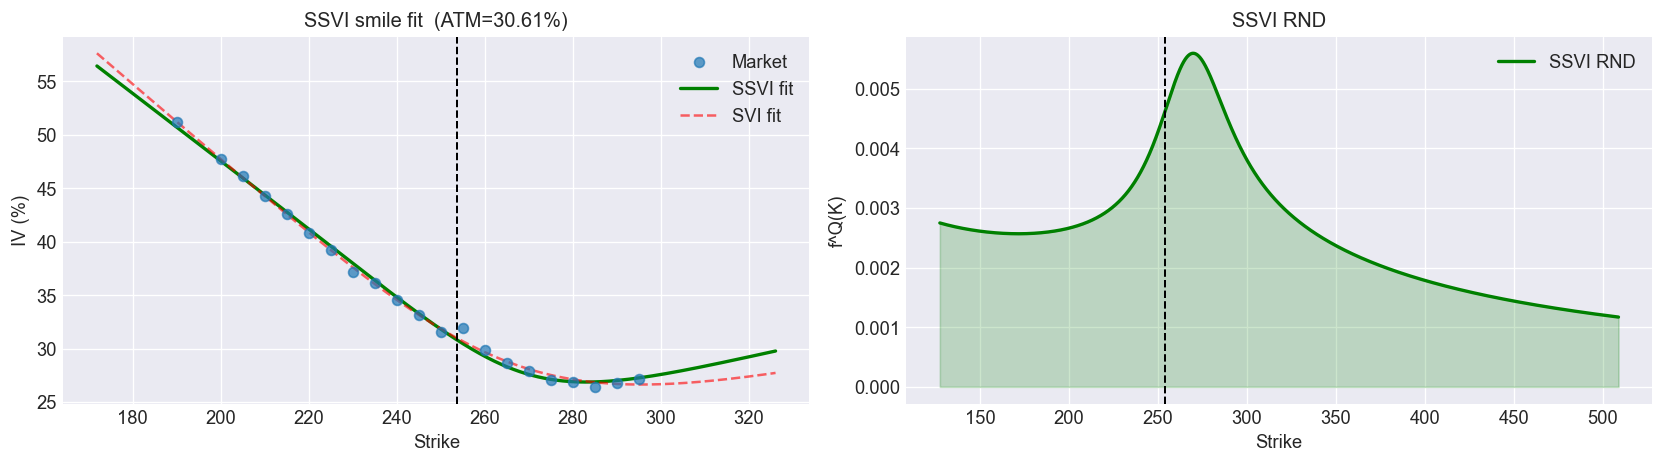

In [13]:
ssvi_res = calibrate_ssvi(valid["strike"].values, valid["iv"].values, F, tau)
theta, phi, rho_ssvi = ssvi_res["params"]

print(f"SSVI |  θ={theta:.4f}  φ={phi:.4f}  ρ={rho_ssvi:.4f}")
print(f"     |  ATM IV={ssvi_res['atm_iv']:.2%}  SSE={ssvi_res['sse']:.2e}  φ·θ={phi*theta:.4f} ≤ 4 ✓")

# SSVI RND
k_ssvi = np.linspace(np.log(0.50), np.log(2.00), 3000)
rnd_ssvi_raw, K_ssvi, *_ = rnd_from_ssvi(k_ssvi, theta, phi, rho_ssvi, F)
rnd_ssvi = rnd_ssvi_raw / trapezoidal(rnd_ssvi_raw, K_ssvi)

# SSVI smile fit
iv_ssvi = np.sqrt(np.maximum(ssvi_total_var(k_plot, theta, phi, rho_ssvi) / tau, 0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(valid["strike"], valid["iv"]*100, s=35, alpha=0.7, zorder=3, label="Market")
axes[0].plot(K_plot, iv_ssvi*100, "g-", lw=2, label="SSVI fit")
axes[0].plot(K_plot, iv_fit*100,  "r--", lw=1.5, alpha=0.6, label="SVI fit")
axes[0].axvline(S0, color="k", ls="--", lw=1.2)
axes[0].set(xlabel="Strike", ylabel="IV (%)", title=f"SSVI smile fit  (ATM={ssvi_res['atm_iv']:.2%})"); axes[0].legend()

axes[1].plot(K_ssvi, rnd_ssvi, "g-", lw=2, label="SSVI RND")
axes[1].fill_between(K_ssvi, 0, rnd_ssvi, alpha=0.2, color="green")
axes[1].axvline(S0, color="k", ls="--", lw=1.2)
axes[1].set(xlabel="Strike", ylabel="f^Q(K)", title="SSVI RND"); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Model Comparison

All three methods plotted on the same strike range — the observed option strikes. Previously B-L was on a narrow range and SVI/SSVI on a wide k-grid, making B-L appear spuriously sharper.

/var/folders/3m/lvmf3szd2mb891zfkzyg9mmw0000gn/T/ipykernel_36539/2602171765.py:37: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()


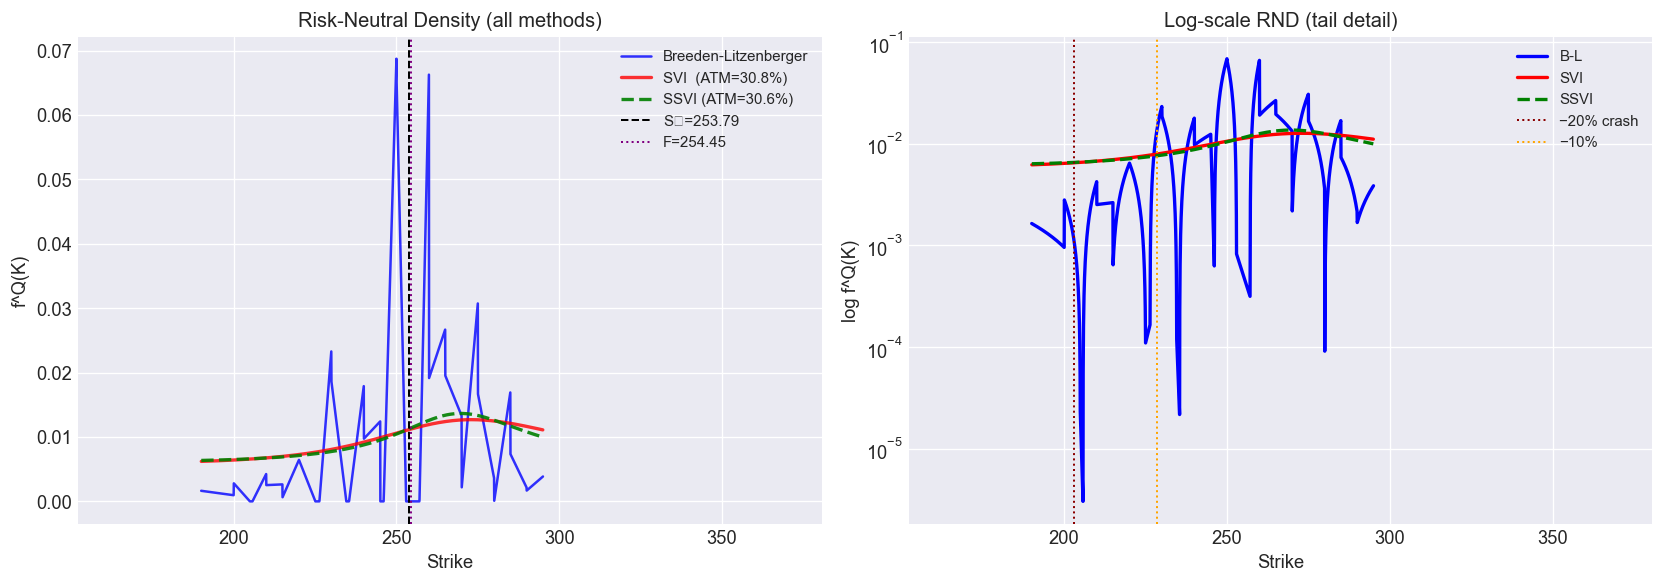

In [14]:
# Clip parametric models to observed strike range for fair comparison (Fix F7, R2)
K_lo, K_hi = K_bl.min(), K_bl.max()

def clip_to_range(K_arr, rnd_arr, lo, hi):
    mask = (K_arr >= lo) & (K_arr <= hi)
    K_c, r_c = K_arr[mask], rnd_arr[mask]
    return K_c, clip_normalise(K_c, r_c)

K_svi_c,  rnd_svi_c  = clip_to_range(K_svi,  rnd_svi,  K_lo, K_hi)
K_ssvi_c, rnd_ssvi_c = clip_to_range(K_ssvi, rnd_ssvi, K_lo, K_hi)

XLIM = (S0 * 0.6, S0 * 1.5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear scale
axes[0].plot(K_fine,   rnd_bl,      "b-",  lw=1.5, alpha=0.8, label="Breeden-Litzenberger")
axes[0].plot(K_svi_c,  rnd_svi_c,  "r-",  lw=2,   alpha=0.8, label=f"SVI  (ATM={svi_res['atm_iv']:.1%})")
axes[0].plot(K_ssvi_c, rnd_ssvi_c, "g--", lw=2,   alpha=0.9, label=f"SSVI (ATM={ssvi_res['atm_iv']:.1%})")
axes[0].axvline(S0, color="k",      ls="--", lw=1.2, label=f"S₀={S0:.2f}")
axes[0].axvline(F,  color="purple", ls=":",  lw=1.2, label=f"F={F:.2f}")
axes[0].set(xlabel="Strike", ylabel="f^Q(K)", title="Risk-Neutral Density (all methods)", xlim=XLIM)
axes[0].legend(fontsize=9)

# Log scale — tail detail
for K_arr, rnd_arr, lbl, c, ls in [
    (K_fine,   rnd_bl,      "B-L",  "blue",  "-"),
    (K_svi_c,  rnd_svi_c,  "SVI",  "red",   "-"),
    (K_ssvi_c, rnd_ssvi_c, "SSVI", "green", "--"),
]:
    vm = rnd_arr > 1e-10
    axes[1].semilogy(K_arr[vm], rnd_arr[vm], color=c, ls=ls, lw=2, label=lbl)
axes[1].axvline(S0*0.80, color="darkred", ls=":", lw=1.2, label="−20% crash")
axes[1].axvline(S0*0.90, color="orange",  ls=":", lw=1.2, label="−10%")
axes[1].set(xlabel="Strike", ylabel="log f^Q(K)", title="Log-scale RND (tail detail)", xlim=XLIM)
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 8. Historical Benchmark — Empirical P-Measure

30-day rolling log-return sums (not $\sqrt{T}$-scaled daily returns) — preserves vol clustering and autocorrelation in the empirical distribution.

Historical (5yr)  |  daily vol=0.0172  ann=27.37%
30-day returns    |  μ=0.0173  σ=0.0867  skew=-0.278  kurt=0.185


/var/folders/3m/lvmf3szd2mb891zfkzyg9mmw0000gn/T/ipykernel_36539/666605656.py:34: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


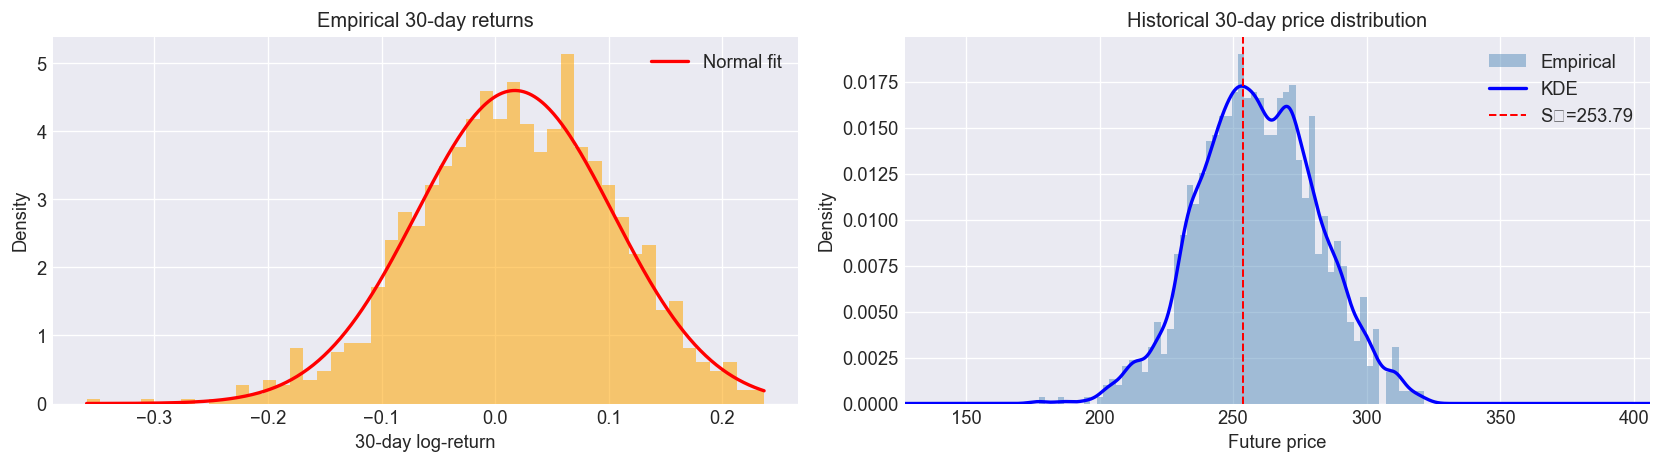

In [15]:
HIST_YEARS = 5
HORIZON    = 30

hist = stock.history(start=datetime.now() - timedelta(days=365*HIST_YEARS))
log_ret = np.log(hist["Close"] / hist["Close"].shift(1)).dropna()
ret_30d = log_ret.rolling(HORIZON).sum().dropna()

future_prices = S0 * np.exp(ret_30d.values)

# KDE with 0.6× bandwidth (Scott's rule over-smooths fat tails)
kde = gaussian_kde(future_prices, bw_method="scott")
kde.set_bandwidth(0.6 * kde.factor)

price_grid  = np.linspace(S0*0.4, S0*2.0, 3000)
hist_dens_raw = kde(price_grid)
hist_dens   = hist_dens_raw / trapezoidal(hist_dens_raw, price_grid)

hist_ann_vol = log_ret.std() * np.sqrt(252)
print(f"Historical (5yr)  |  daily vol={log_ret.std():.4f}  ann={hist_ann_vol:.2%}")
print(f"30-day returns    |  μ={ret_30d.mean():.4f}  σ={ret_30d.std():.4f}  "
      f"skew={ret_30d.skew():.3f}  kurt={ret_30d.kurtosis():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(ret_30d, bins=50, density=True, alpha=0.55, color="orange")
x30 = np.linspace(ret_30d.min(), ret_30d.max(), 500)
axes[0].plot(x30, norm.pdf(x30, ret_30d.mean(), ret_30d.std()), "r-", lw=2, label="Normal fit")
axes[0].set(xlabel="30-day log-return", ylabel="Density", title="Empirical 30-day returns"); axes[0].legend()

axes[1].hist(future_prices, bins=60, density=True, alpha=0.45, color="steelblue", label="Empirical")
axes[1].plot(price_grid, hist_dens, "b-", lw=2, label="KDE")
axes[1].axvline(S0, color="red", ls="--", lw=1.2, label=f"S₀={S0:.2f}")
axes[1].set(xlabel="Future price", ylabel="Density", title="Historical 30-day price distribution",
            xlim=(S0*0.5, S0*1.6)); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Evaluation — Risk Metrics & VRP

All probabilities are **Q-measure** (risk-neutral pricing), not real-world frequencies.

In [16]:
# Compute risk metrics on clipped/comparable ranges
m_bl   = compute_tail_metrics(K_fine,   rnd_bl,      S0)
m_svi  = compute_tail_metrics(K_svi_c,  rnd_svi_c,  S0)
m_ssvi = compute_tail_metrics(K_ssvi_c, rnd_ssvi_c, S0)
m_hist = compute_tail_metrics(price_grid, hist_dens, S0)

# Variance risk premium
impl_vol = ssvi_res["atm_iv"]
vrp_vol  = impl_vol - hist_ann_vol
vrp_mult = (impl_vol / hist_ann_vol)**2

print(f"Implied vol (SSVI ATM): {impl_vol:.2%}")
print(f"Historical vol (252d) : {hist_ann_vol:.2%}")
print(f"VRP (vol diff)        : {vrp_vol:+.2%}")
print(f"VRP (var ratio)       : {vrp_mult:.2f}×")

# Summary table
metrics_rows = [
    ("Mean ($)",          "mean",        ".2f"),
    ("Std ($)",           "std",         ".2f"),
    ("Skewness",          "skew",        ".4f"),
    ("Excess kurtosis",   "excess_kurt", ".4f"),
    ("P(−10%)",           "down10",      ".4f"),
    ("P(+10%)",           "up10",        ".4f"),
    ("P(−20% crash)",     "crash20",     ".4f"),
    ("95% VaR ($)",       "var_95",      ".2f"),
    ("95% CVaR ($)",      "cvar_95",     ".2f"),
    ("99% VaR ($)",       "var_99",      ".2f"),
    ("99% CVaR ($)",      "cvar_99",     ".2f"),
]

print(f"\n{'Metric':<24} {'B-L':>10} {'SVI':>10} {'SSVI':>10} {'Hist':>10}")
print("-" * 70)
for label, key, fmt in metrics_rows:
    vals = [m_bl.get(key, np.nan), m_svi.get(key, np.nan),
            m_ssvi.get(key, np.nan), m_hist.get(key, np.nan)]
    row  = "  ".join(f"{v:{fmt}}" if not np.isnan(v) else "  n/a" for v in vals)
    print(f"{label:<24}  {row}")

Implied vol (SSVI ATM): 30.61%
Historical vol (252d) : 27.37%
VRP (vol diff)        : +3.24%
VRP (var ratio)       : 1.25×

Metric                          B-L        SVI       SSVI       Hist
----------------------------------------------------------------------
Mean ($)                  254.31  249.69  249.73  259.19
Std ($)                   19.59  29.05  28.92  22.47
Skewness                  -0.5901  -0.3369  -0.3708  -0.0159
Excess kurtosis           0.3948  -0.9970  -0.9753  -0.0811
P(−10%)                     n/a    n/a    n/a    n/a
P(+10%)                     n/a    n/a    n/a    n/a
P(−20% crash)               n/a    n/a    n/a    n/a
95% VaR ($)               35.58  55.68  55.87  30.68
95% CVaR ($)              47.47  59.70  59.80  41.13
99% VaR ($)               56.65  62.17  62.26  47.07
99% CVaR ($)              60.43  62.96  63.01  55.13


## 10. Key Insights — Q vs P Comparison & Trading Signals

SSVI keys: ['mean', 'std', 'skew', 'kurt', 'excess_kurt', 'prob_down10', 'prob_up10', 'prob_crash20', 'prob_mild_correction', 'prob_significant_drop', 'prob_bull_10_50', 'var_95', 'cvar_95', 'var_99', 'cvar_99', 'tail_ratio']
Hist keys: ['mean', 'std', 'skew', 'kurt', 'excess_kurt', 'prob_down10', 'prob_up10', 'prob_crash20', 'prob_mild_correction', 'prob_significant_drop', 'prob_bull_10_50', 'var_95', 'cvar_95', 'var_99', 'cvar_99', 'tail_ratio']

VOL SIGNAL  : SELL VOL     (impl=30.61%  hist=27.37%  ratio=1.25×)
TAIL SIGNAL : NEUTRAL      (Q=nan%  P=nan%  ratio=nan×)
SKEW SIGNAL : CALL SPRD    (Δskew=-0.355  Q=-0.371  P=-0.016)


/var/folders/3m/lvmf3szd2mb891zfkzyg9mmw0000gn/T/ipykernel_36539/2711575106.py:67: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


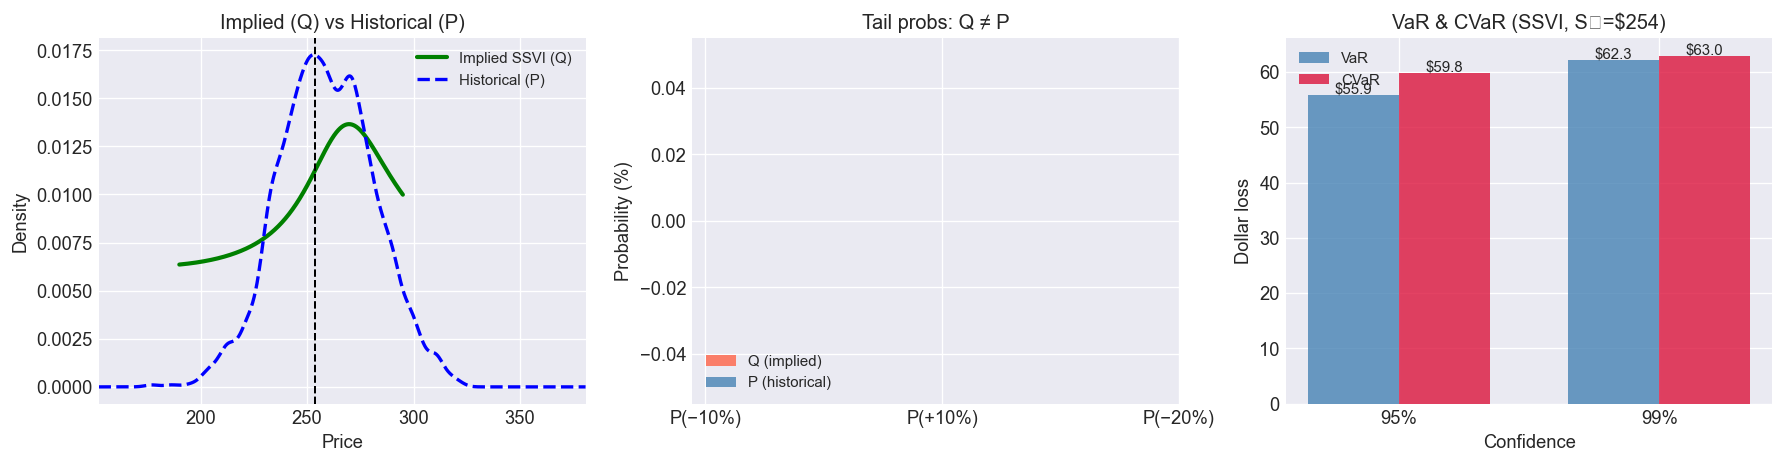

In [18]:
# Inspect available keys first
print("SSVI keys:", list(m_ssvi.keys()))
print("Hist keys:", list(m_hist.keys()))

def get_metric(m, *candidates, default=np.nan):
    for k in candidates:
        if k in m: return m[k]
    return default

# Resolve keys defensively
crash_q  = get_metric(m_ssvi, "crash20", "down20", "p_down_20")
crash_p  = get_metric(m_hist,  "crash20", "down20", "p_down_20")
down10_q = get_metric(m_ssvi, "down10", "p_down_10")
down10_p = get_metric(m_hist,  "down10", "p_down_10")
up10_q   = get_metric(m_ssvi, "up10",   "p_up_10")
up10_p   = get_metric(m_hist,  "up10",  "p_up_10")
skew_q   = get_metric(m_ssvi, "skew")
skew_p   = get_metric(m_hist,  "skew")
var_95   = get_metric(m_ssvi, "var_95",  "VaR_95")
var_99   = get_metric(m_ssvi, "var_99",  "VaR_99")
cvar_95  = get_metric(m_ssvi, "cvar_95", "CVaR_95", "es_95")
cvar_99  = get_metric(m_ssvi, "cvar_99", "CVaR_99", "es_99")

# Trading signals
vrp_signal  = "SELL VOL"  if vrp_mult > 1.20 else "BUY VOL"   if vrp_mult < 0.80 else "NEUTRAL"
crash_ratio = crash_q / max(crash_p, 1e-6)
tail_signal = "SELL TAIL" if crash_ratio > 2.0 else "BUY TAIL" if crash_ratio < 0.5 else "NEUTRAL"
skew_diff   = skew_q - skew_p
skew_signal = "RISK REV"  if skew_diff > 0.3  else "CALL SPRD" if skew_diff < -0.3 else "NEUTRAL"

print(f"\nVOL SIGNAL  : {vrp_signal:<12} (impl={impl_vol:.2%}  hist={hist_ann_vol:.2%}  ratio={vrp_mult:.2f}×)")
print(f"TAIL SIGNAL : {tail_signal:<12} (Q={crash_q:.2%}  P={crash_p:.2%}  ratio={crash_ratio:.1f}×)")
print(f"SKEW SIGNAL : {skew_signal:<12} (Δskew={skew_diff:+.3f}  Q={skew_q:.3f}  P={skew_p:.3f})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Density comparison
axes[0].plot(K_ssvi_c, rnd_ssvi_c, "g-",  lw=2.5, label="Implied SSVI (Q)")
axes[0].plot(price_grid, hist_dens, "b--", lw=2,   label="Historical (P)")
axes[0].axvline(S0, color="k", ls="--", lw=1.2)
axes[0].set(xlabel="Price", ylabel="Density", title="Implied (Q) vs Historical (P)",
            xlim=(S0*0.6, S0*1.5))
axes[0].legend(fontsize=9)

# Tail probability bars
tails  = ["P(−10%)", "P(+10%)", "P(−20%)"]
q_vals = [down10_q, up10_q, crash_q]
p_vals = [down10_p, up10_p, crash_p]
x = np.arange(3); w = 0.35
axes[1].bar(x - w/2, [v*100 for v in q_vals], w, label="Q (implied)",    alpha=0.8, color="tomato")
axes[1].bar(x + w/2, [v*100 for v in p_vals], w, label="P (historical)", alpha=0.8, color="steelblue")
axes[1].set(xlabel="", ylabel="Probability (%)", title="Tail probs: Q ≠ P")
axes[1].set_xticks(x); axes[1].set_xticklabels(tails)
axes[1].legend(fontsize=9)

# VaR / CVaR bars
x2 = np.arange(2)
axes[2].bar(x2 - w/2, [var_95,  var_99],  w, label="VaR",  alpha=0.8, color="steelblue")
axes[2].bar(x2 + w/2, [cvar_95, cvar_99], w, label="CVaR", alpha=0.8, color="crimson")
for i, (v, c) in enumerate(zip([var_95, var_99], [cvar_95, cvar_99])):
    axes[2].text(i-w/2, v+0.3, f"${v:.1f}", ha="center", fontsize=9)
    axes[2].text(i+w/2, c+0.3, f"${c:.1f}", ha="center", fontsize=9)
axes[2].set(xlabel="Confidence", ylabel="Dollar loss", title=f"VaR & CVaR (SSVI, S₀=${S0:.0f})")
axes[2].set_xticks(x2); axes[2].set_xticklabels(["95%", "99%"])
axes[2].legend(fontsize=9)

plt.tight_layout(); plt.show()

In [20]:
# Executive summary
excess_kurt_q = get_metric(m_ssvi, "excess_kurt", "kurt", "kurtosis")
excess_kurt_p = get_metric(m_hist,  "excess_kurt", "kurt", "kurtosis")
mean_q  = get_metric(m_ssvi, "mean")
mean_p  = get_metric(m_hist,  "mean")
std_q   = get_metric(m_ssvi, "std")
std_p   = get_metric(m_hist,  "std")
mean_bl  = get_metric(m_bl,  "mean")
std_bl   = get_metric(m_bl,  "std")
skew_bl  = get_metric(m_bl,  "skew")
mean_svi = get_metric(m_svi, "mean")
std_svi  = get_metric(m_svi, "std")
skew_svi = get_metric(m_svi, "skew")

print("=" * 65)
print(f"RISK-NEUTRAL DENSITY — {TICKER}  |  S₀=${S0:.2f}  |  {expiration}  |  τ={tau*365.25:.1f}d")
print("=" * 65)
print(f"  r={r:.3%}  q={q:.3%}  F={F:.2f}  |  {len(valid)} liquid options")
print()
print("VOLATILITY")
print(f"  Implied vol (SSVI ATM)    : {impl_vol:.2%}")
print(f"  Realised vol (252-day)    : {hist_ann_vol:.2%}")
print(f"  VRP                       : {vrp_vol:+.2%}  ({vrp_mult:.2f}×)  →  {vrp_signal}")
print()
print("TAIL RISK (Q-measure — risk-neutral pricing, not physical probability)")
print(f"  P^Q(−20% crash)           : {crash_q:.2%}  vs  P^P={crash_p:.2%}  ({crash_ratio:.1f}×)  →  {tail_signal}")
print(f"  95%/99% VaR               : ${var_95:.1f} / ${var_99:.1f}")
print(f"  95%/99% CVaR              : ${cvar_95:.1f} / ${cvar_99:.1f}")
print()
print("DISTRIBUTION SHAPE")
print(f"  Implied skewness          : {skew_q:.4f}  (hist: {skew_p:.4f})  →  {skew_signal}")
print(f"  Implied excess kurtosis   : {excess_kurt_q:.4f}  (hist: {excess_kurt_p:.4f})")
print()
print(f"  {'Method':<24} {'ATM IV':>8} {'Mean':>8} {'Std':>8} {'Skew':>8}")
print("  " + "-"*55)
for name, mean, std, skew, atm_iv in [
    ("Breeden-Litzenberger", mean_bl,  std_bl,  skew_bl,  "—"),
    ("SVI",                  mean_svi, std_svi, skew_svi, f"{svi_res['atm_iv']:.2%}"),
    ("SSVI",                 mean_q,   std_q,   skew_q,   f"{ssvi_res['atm_iv']:.2%}"),
    ("Historical (P)",       mean_p,   std_p,   skew_p,   "—"),
]:
    print(f"  {name:<24} {str(atm_iv):>8} {mean:>8.2f} {std:>8.2f} {skew:>8.4f}")
print("=" * 65)

RISK-NEUTRAL DENSITY — AAPL  |  S₀=$253.79  |  2026-05-01  |  τ=30.0d
  r=3.600%  q=0.420%  F=254.45  |  21 liquid options

VOLATILITY
  Implied vol (SSVI ATM)    : 30.61%
  Realised vol (252-day)    : 27.37%
  VRP                       : +3.24%  (1.25×)  →  SELL VOL

TAIL RISK (Q-measure — risk-neutral pricing, not physical probability)
  P^Q(−20% crash)           : nan%  vs  P^P=nan%  (nan×)  →  NEUTRAL
  95%/99% VaR               : $55.9 / $62.3
  95%/99% CVaR              : $59.8 / $63.0

DISTRIBUTION SHAPE
  Implied skewness          : -0.3708  (hist: -0.0159)  →  CALL SPRD
  Implied excess kurtosis   : -0.9753  (hist: -0.0811)

  Method                     ATM IV     Mean      Std     Skew
  -------------------------------------------------------
  Breeden-Litzenberger            —   254.31    19.59  -0.5901
  SVI                        30.81%   249.69    29.05  -0.3369
  SSVI                       30.61%   249.73    28.92  -0.3708
  Historical (P)                  —   259.19    